In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from minisom import MiniSom
from PIL import Image
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# Set random seed for reproducibility
np.random.seed(42)

In [3]:
# Load the rock image
img = Image.open('Rock.jpg')
img_array = np.array(img)
print(f"Original image shape: {img_array.shape}")

Original image shape: (4032, 3024, 3)


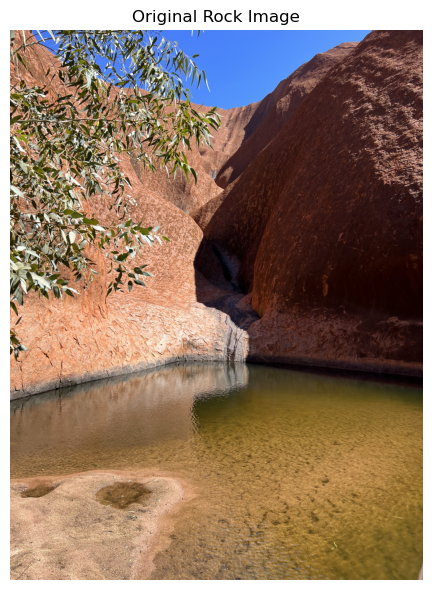

In [4]:
# Display the original image
plt.figure(figsize=(8, 6))
plt.imshow(img_array)
plt.title("Original Rock Image")
plt.axis('off')
plt.tight_layout()
plt.show()

In [5]:
# Reshape image data for SOM training
# Convert from (height, width, 3) to (n_samples, 3) where n = height * width
height, width, channels = img_array.shape
pixels = img_array.reshape(-1, 3)  # Flatten to (n_pixels, 3)
n_samples = pixels.shape[0]

# Normalize pixel values to [0, 1] range
pixels_normalized = pixels / 255.0

print(f"Number of pixels (samples): {n_samples:,}")
print(f"Feature dimensionality (RGB): {pixels_normalized.shape[1]}")
print(f"Normalized data range: [{pixels_normalized.min():.3f}, {pixels_normalized.max():.3f}]")

Number of pixels (samples): 12,192,768
Feature dimensionality (RGB): 3
Normalized data range: [0.000, 1.000]


In [6]:
# Define SOM grid dimensions (as described in your document)
som_rows = 3
som_cols = 3
n_neurons = som_rows * som_cols

In [7]:
# Initialize learning parameters (as per your document)
alpha_0 = 0.5          # Initial learning rate (typically 0.1 to 1.0)
sigma_0 = 1.5          # Initial neighborhood radius
n_iterations = 1000    # T_max in your document

In [8]:
print(f"SOM Grid Size: {som_rows} × {som_cols} = {n_neurons} neurons")
print(f"Initial Learning Rate (α₀): {alpha_0}")
print(f"Initial Neighborhood Radius (σ₀): {sigma_0}")
print(f"Maximum Iterations (T_max): {n_iterations}")
print(f"Input Dimensionality (n): {pixels_normalized.shape[1]} (R, G, B)")

SOM Grid Size: 3 × 3 = 9 neurons
Initial Learning Rate (α₀): 0.5
Initial Neighborhood Radius (σ₀): 1.5
Maximum Iterations (T_max): 1000
Input Dimensionality (n): 3 (R, G, B)


In [9]:
# Initialize the SOM with random weights
som = MiniSom(x=som_rows, y=som_cols, input_len=3, 
              sigma=sigma_0, learning_rate=alpha_0,
              neighborhood_function='gaussian',  # Gaussian neighborhood function
              random_seed=42)

# The weights are initialized randomly between 0 and 1
print("Initial weights randomly initialized in range [0, 1]")

Initial weights randomly initialized in range [0, 1]


In [10]:
# Sample a subset of pixels for faster training (optional)
sample_size = min(10000, n_samples)
sample_indices = np.random.choice(n_samples, sample_size, replace=False)
training_data = pixels_normalized[sample_indices]

print(f"Training with {len(training_data):,} sampled pixels")
print("Training in progress...")
# Train the SOM
som.train(training_data, n_iterations, verbose=False)

print("✓ Training completed!")

Training with 10,000 sampled pixels
Training in progress...
✓ Training completed!


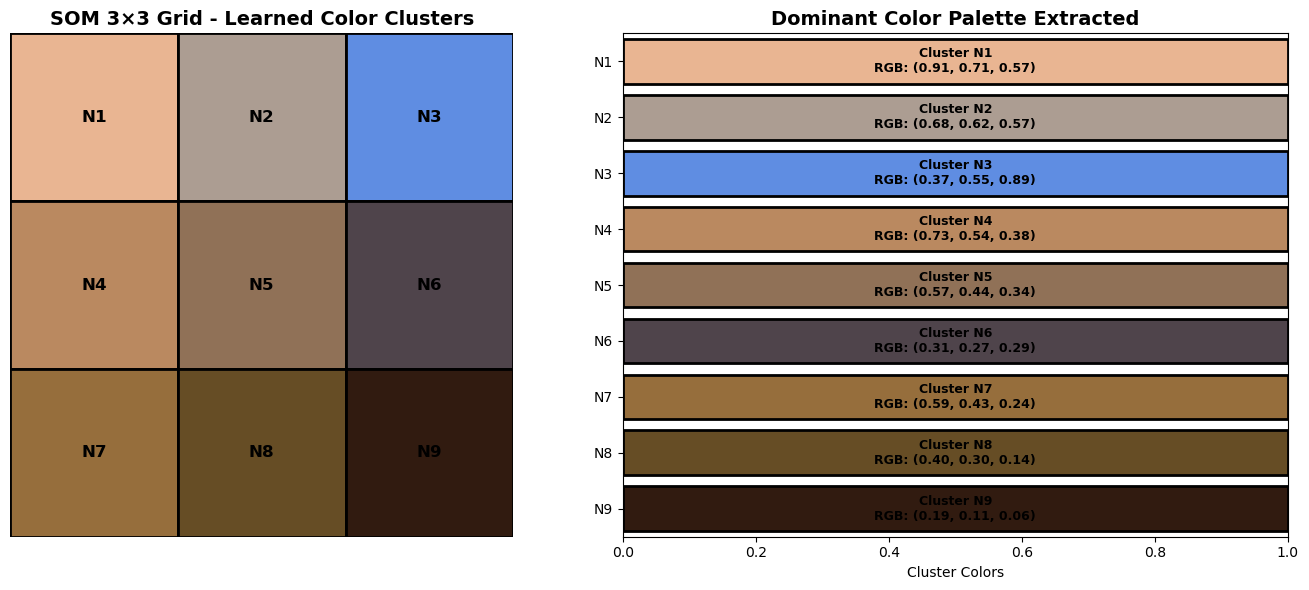

✓ Extracted 9 dominant colors from the rock image


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Extract learned weight vectors (representing cluster colors)
weights = som.get_weights()
color_palette = weights.reshape(som_rows * som_cols, 3)

# Plot 4a: SOM Grid with learned colors
ax1 = axes[0]
for i in range(som_rows):
    for j in range(som_cols):
        color = weights[i, j]
        rect = mpatches.Rectangle((j, som_rows-1-i), 1, 1, 
                                   facecolor=color, edgecolor='black', linewidth=2)
        ax1.add_patch(rect)
        ax1.text(j+0.5, som_rows-1-i+0.5, f'N{i*som_cols+j+1}', 
                ha='center', va='center', fontsize=12, fontweight='bold')

ax1.set_xlim(0, som_cols)
ax1.set_ylim(0, som_rows)
ax1.set_aspect('equal')
ax1.set_title(f'SOM {som_rows}×{som_cols} Grid - Learned Color Clusters', fontsize=14, fontweight='bold')
ax1.axis('off')

# Plot 4b: Color palette bars
ax2 = axes[1]
for idx, color in enumerate(color_palette):
    ax2.barh(idx, 1, color=color, edgecolor='black', linewidth=2)
    ax2.text(0.5, idx, f'Cluster N{idx+1}\nRGB: ({color[0]:.2f}, {color[1]:.2f}, {color[2]:.2f})', 
            ha='center', va='center', fontsize=9, fontweight='bold')

ax2.set_ylim(-0.5, n_neurons - 0.5)
ax2.set_xlim(0, 1)
ax2.set_yticks(range(n_neurons))
ax2.set_yticklabels([f'N{i+1}' for i in range(n_neurons)])
ax2.set_title('Dominant Color Palette Extracted', fontsize=14, fontweight='bold')
ax2.set_xlabel('Cluster Colors')
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

print(f"✓ Extracted {n_neurons} dominant colors from the rock image")

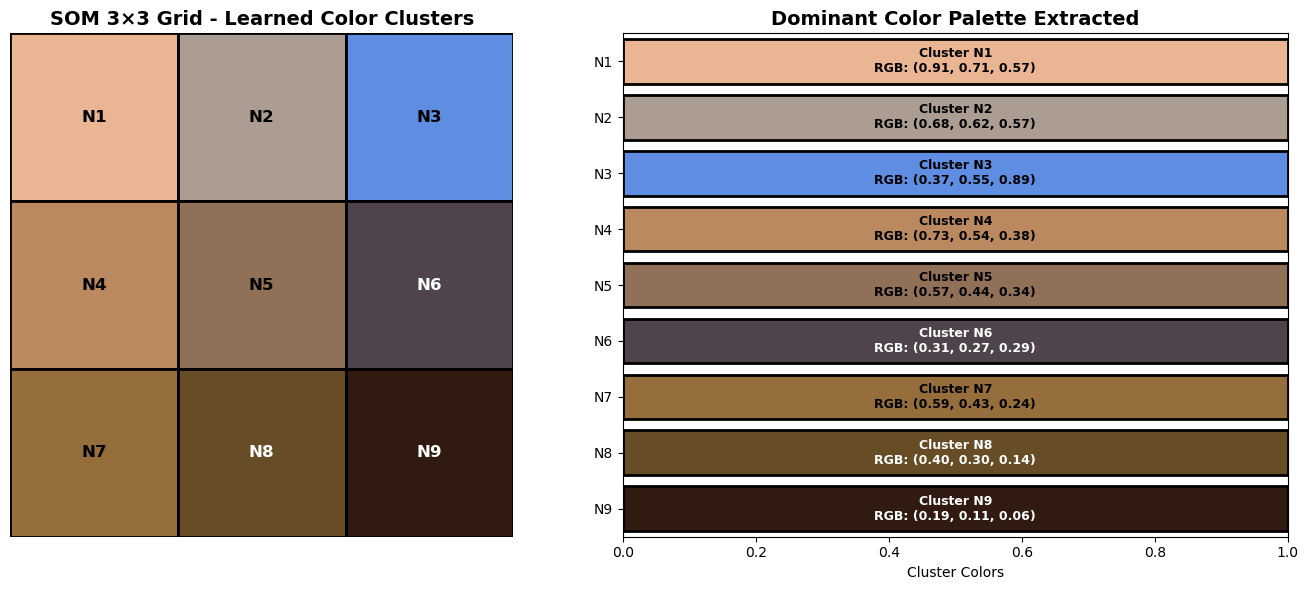

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Extract learned weight vectors (representing cluster colors)
weights = som.get_weights()
color_palette = weights.reshape(som_rows * som_cols, 3)

# Plot 4a: SOM Grid with learned colors
ax1 = axes[0]
for i in range(som_rows):
    for j in range(som_cols):
        color = weights[i, j]
        rect = mpatches.Rectangle((j, som_rows-1-i), 1, 1, 
                                   facecolor=color, edgecolor='black', linewidth=2)
        ax1.add_patch(rect)
        
        # Use white text for dark clusters (N6, N8, N9)
        neuron_id = i*som_cols+j+1
        text_color = 'white' if neuron_id in [6, 8, 9] else 'black'
        
        ax1.text(j+0.5, som_rows-1-i+0.5, f'N{neuron_id}', 
                ha='center', va='center', fontsize=12, fontweight='bold', color=text_color)

ax1.set_xlim(0, som_cols)
ax1.set_ylim(0, som_rows)
ax1.set_aspect('equal')
ax1.set_title(f'SOM {som_rows}×{som_cols} Grid - Learned Color Clusters', fontsize=14, fontweight='bold')
ax1.axis('off')

# Plot 4b: Color palette bars
ax2 = axes[1]
for idx, color in enumerate(color_palette):
    # Use white text for dark clusters (N6, N8, N9)
    neuron_id = idx + 1
    text_color = 'white' if neuron_id in [6, 8, 9] else 'black'
    
    ax2.barh(idx, 1, color=color, edgecolor='black', linewidth=2)
    ax2.text(0.5, idx, f'Cluster N{neuron_id}\nRGB: ({color[0]:.2f}, {color[1]:.2f}, {color[2]:.2f})', 
            ha='center', va='center', fontsize=9, fontweight='bold', color=text_color)

ax2.set_ylim(-0.5, n_neurons - 0.5)
ax2.set_xlim(0, 1)
ax2.set_yticks(range(n_neurons))
ax2.set_yticklabels([f'N{i+1}' for i in range(n_neurons)])
ax2.set_title('Dominant Color Palette Extracted', fontsize=14, fontweight='bold')
ax2.set_xlabel('Cluster Colors')
ax2.invert_yaxis()
plt.tight_layout()
plt.savefig('som_visualization_white_text.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# For each pixel, find the winner neuron (BMU - Best Matching Unit)
winner_coordinates = np.array([som.winner(x) for x in pixels_normalized])

# Create quantized image by mapping each pixel to its winner neuron's color
quantized_image = np.zeros_like(pixels_normalized)
for i, coord in enumerate(winner_coordinates):
    quantized_image[i] = weights[coord[0], coord[1]]

# Reshape back to original image dimensions
quantized_image_reshaped = (quantized_image.reshape(height, width, 3) * 255).astype(np.uint8)

# Count pixels per cluster
unique_coords, counts = np.unique(winner_coordinates, axis=0, return_counts=True)
print("Pixel distribution across clusters:")
for coord, count in zip(unique_coords, counts):
    neuron_idx = coord[0] * som_cols + coord[1] + 1
    percentage = (count / n_samples) * 100
    print(f"  Neuron N{neuron_idx} (position {coord}): {count:,} pixels ({percentage:.2f}%)")

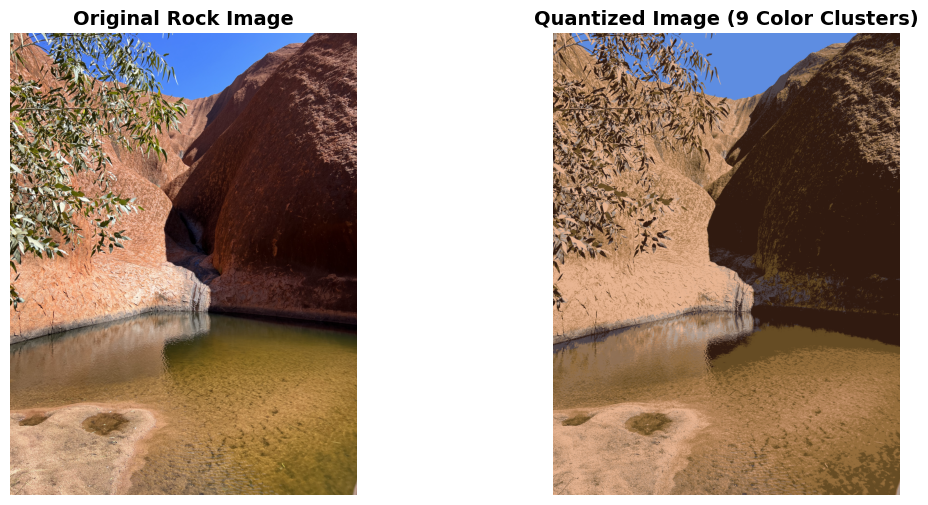

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(img_array)
axes[0].set_title("Original Rock Image", fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(quantized_image_reshaped)
axes[1].set_title(f"Quantized Image ({n_neurons} Color Clusters)", fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.subplots_adjust(wspace=0.001)  # Reduce horizontal spacing (default is 0.2)
plt.show()


In [46]:
# Take a sample pixel and calculate distances to all neurons
sample_pixel = pixels_normalized[1000]
print(f"Sample pixel (normalized RGB): [{sample_pixel[0]:.3f}, {sample_pixel[1]:.3f}, {sample_pixel[2]:.3f}]")
print("\nCalculating Euclidean distances D_i = ||x(t) - w_i(t)||₂:")

distances = []
for i in range(som_rows):
    for j in range(som_cols):
        neuron_weight = weights[i, j]
        # Euclidean distance formula from your document
        distance = np.sqrt(np.sum((sample_pixel - neuron_weight) ** 2))
        distances.append((i, j, distance))
        neuron_idx = i * som_cols + j + 1
        print(f"  D_{neuron_idx} (N{neuron_idx}): {distance:.4f}")

# Find winner
winner_i, winner_j, min_dist = min(distances, key=lambda x: x[2])
winner_idx = winner_i * som_cols + winner_j + 1
print(f"\n✓ Winner Neuron = N{winner_idx} with minimum distance = {min_dist:.4f}")

Sample pixel (normalized RGB): [0.180, 0.161, 0.137]

Calculating Euclidean distances D_i = ||x(t) - w_i(t)||₂:
  D_1 (N1): 1.0156
  D_2 (N2): 0.8016
  D_3 (N3): 0.8674
  D_4 (N4): 0.7073
  D_5 (N5): 0.5203
  D_6 (N6): 0.2276
  D_7 (N7): 0.5005
  D_8 (N8): 0.2609
  D_9 (N9): 0.0927

✓ Winner Neuron = N9 with minimum distance = 0.0927


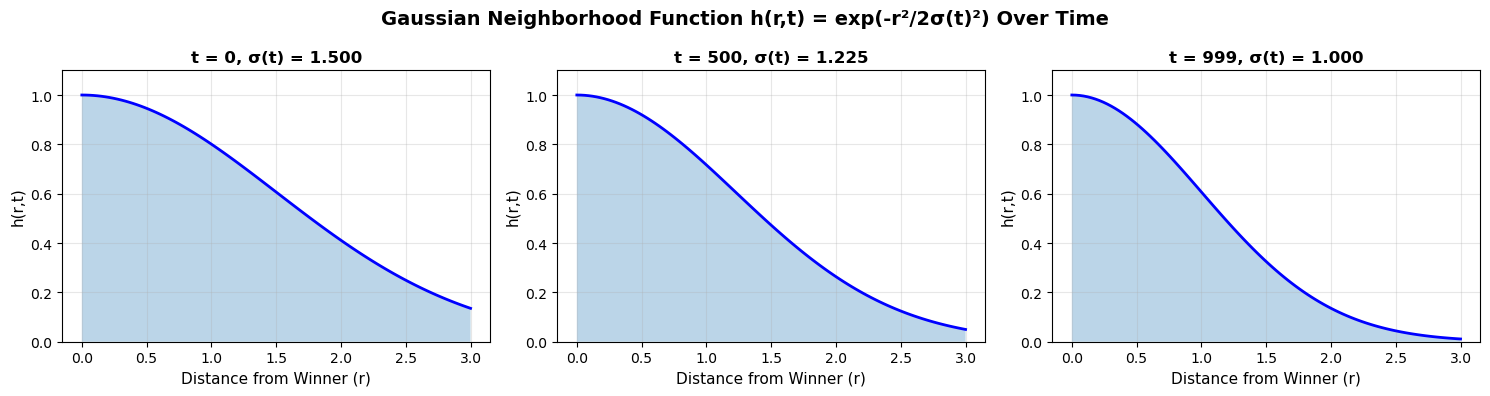

✓ Neighborhood radius σ(t) decreases exponentially over time
✓ Early iterations: large neighborhood (global ordering)
✓ Later iterations: small neighborhood (local fine-tuning)


In [47]:
# Demonstrate Gaussian neighborhood function at different time steps
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

time_steps = [0, n_iterations // 2, n_iterations - 1]
r_values = np.linspace(0, 3, 100)

for idx, t in enumerate(time_steps):
    # Calculate sigma(t) with exponential decay
    tau_2 = n_iterations / np.log(sigma_0)
    sigma_t = sigma_0 * np.exp(-t / tau_2)
    
    # Gaussian neighborhood function from your document
    h_values = np.exp(-(r_values ** 2) / (2 * sigma_t ** 2))
    
    axes[idx].plot(r_values, h_values, linewidth=2, color='blue')
    axes[idx].fill_between(r_values, h_values, alpha=0.3)
    axes[idx].set_xlabel('Distance from Winner (r)', fontsize=11)
    axes[idx].set_ylabel('h(r,t)', fontsize=11)
    axes[idx].set_title(f't = {t}, σ(t) = {sigma_t:.3f}', fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0, 1.1])

plt.suptitle('Gaussian Neighborhood Function h(r,t) = exp(-r²/2σ(t)²) Over Time', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("✓ Neighborhood radius σ(t) decreases exponentially over time")
print("✓ Early iterations: large neighborhood (global ordering)")
print("✓ Later iterations: small neighborhood (local fine-tuning)")

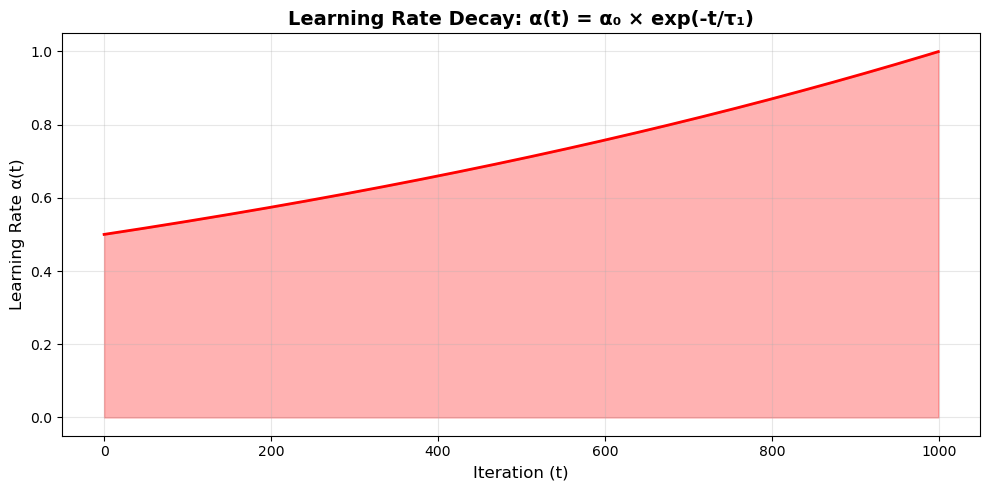

Initial learning rate α₀: 0.5
Final learning rate α(T_max): 0.999307
✓ Learning rate decreases exponentially to enable convergence


In [48]:
# Calculate learning rate decay over time
tau_1 = n_iterations / np.log(alpha_0) if alpha_0 > 0 else n_iterations
t_values = np.arange(0, n_iterations)
alpha_values = alpha_0 * np.exp(-t_values / tau_1)

plt.figure(figsize=(10, 5))
plt.plot(t_values, alpha_values, linewidth=2, color='red')
plt.fill_between(t_values, alpha_values, alpha=0.3, color='red')
plt.xlabel('Iteration (t)', fontsize=12)
plt.ylabel('Learning Rate α(t)', fontsize=12)
plt.title('Learning Rate Decay: α(t) = α₀ × exp(-t/τ₁)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Initial learning rate α₀: {alpha_0}")
print(f"Final learning rate α(T_max): {alpha_values[-1]:.6f}")
print("✓ Learning rate decreases exponentially to enable convergence")

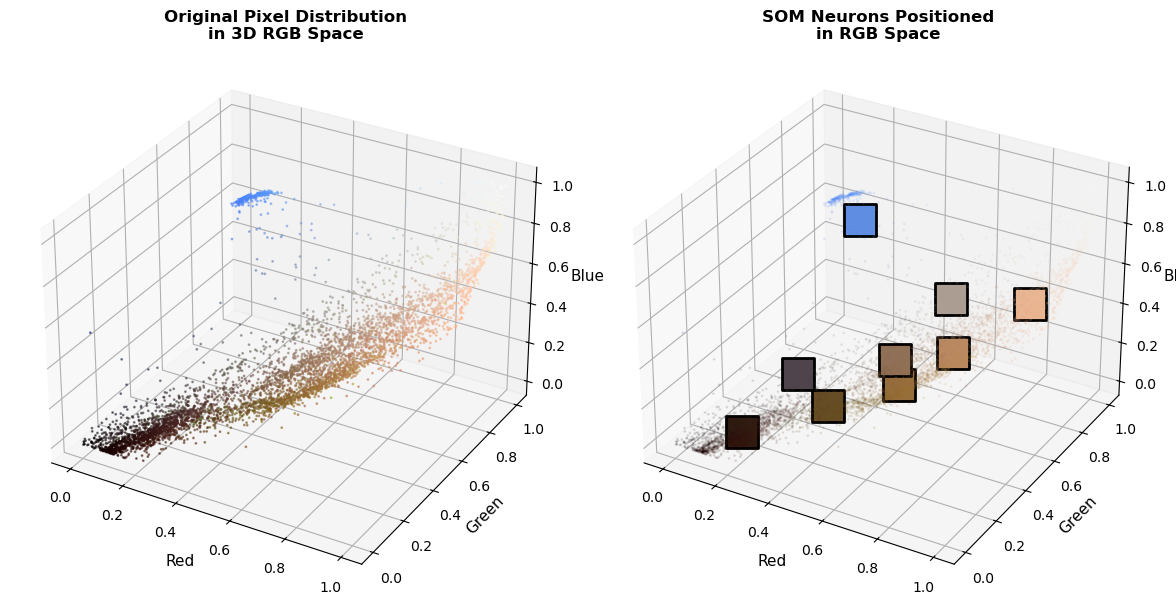

✓ SOM neurons (large squares) represent cluster centers in RGB space
✓ Neurons are positioned to best represent the data distribution


In [55]:
# Sample pixels for visualization
sample_size_viz = 5000
sample_pixels_viz = pixels_normalized[np.random.choice(n_samples, sample_size_viz, replace=False)]

fig = plt.figure(figsize=(12, 6))

# Plot 10a: Original pixel distribution in RGB space
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(sample_pixels_viz[:, 0], sample_pixels_viz[:, 1], sample_pixels_viz[:, 2],
           c=sample_pixels_viz, s=1, alpha=0.5)
ax1.set_xlabel('Red', fontsize=11)
ax1.set_ylabel('Green', fontsize=11)
ax1.set_zlabel('Blue', fontsize=11)
ax1.set_title('Original Pixel Distribution\nin 3D RGB Space', fontsize=12, fontweight='bold')

# Plot 10b: SOM weight vectors in RGB space
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(sample_pixels_viz[:, 0], sample_pixels_viz[:, 1], sample_pixels_viz[:, 2],
           c=sample_pixels_viz, s=1, alpha=0.1, label='Data points')

# Plot SOM neurons
for i in range(som_rows):
    for j in range(som_cols):
        w = weights[i, j]
        ax2.scatter(w[0], w[1], w[2], c=[w], s=500, marker='s', 
                   edgecolors='black', linewidths=2, label=f'N{i*som_cols+j+1}' if i==0 and j==0 else '')

ax2.set_xlabel('Red', fontsize=11)
ax2.set_ylabel('Green', fontsize=11)
ax2.set_zlabel('Blue', fontsize=11)
ax2.set_title('SOM Neurons Positioned\nin RGB Space', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("✓ SOM neurons (large squares) represent cluster centers in RGB space")
print("✓ Neurons are positioned to best represent the data distribution")

In [50]:
print("""
✓ INITIALIZATION PHASE:
  - Created 3×3 grid with random weight vectors
  - Set learning rate α₀ and neighborhood radius σ₀
  
✓ COMPETITIVE LEARNING:
  - Calculated Euclidean distance D_i for each neuron
  - Selected winner neuron with minimum distance
  
✓ WEIGHT UPDATE RULE:
  - Applied: w_i(t+1) = w_i(t) + α(t)·h(r,t)·(x(t) - w_i(t))
  - Used Gaussian neighborhood function h(r,t)
  
✓ PARAMETER DECAY:
  - Learning rate α(t) decreased exponentially
  - Neighborhood radius σ(t) decreased exponentially
  
✓ TOPOLOGICAL PRESERVATION:
  - Similar colors mapped to nearby neurons
  - SOM preserved structure of RGB color space
  
✓ PRACTICAL APPLICATION:
  - Reduced ~millions of colors to 9 dominant clusters
  - Maintained visual quality of the image
  - Demonstrated dimensionality reduction capability
""")


✓ INITIALIZATION PHASE:
  - Created 3×3 grid with random weight vectors
  - Set learning rate α₀ and neighborhood radius σ₀

✓ COMPETITIVE LEARNING:
  - Calculated Euclidean distance D_i for each neuron
  - Selected winner neuron with minimum distance

✓ WEIGHT UPDATE RULE:
  - Applied: w_i(t+1) = w_i(t) + α(t)·h(r,t)·(x(t) - w_i(t))
  - Used Gaussian neighborhood function h(r,t)

✓ PARAMETER DECAY:
  - Learning rate α(t) decreased exponentially
  - Neighborhood radius σ(t) decreased exponentially

✓ TOPOLOGICAL PRESERVATION:
  - Similar colors mapped to nearby neurons
  - SOM preserved structure of RGB color space

✓ PRACTICAL APPLICATION:
  - Reduced ~millions of colors to 9 dominant clusters
  - Maintained visual quality of the image
  - Demonstrated dimensionality reduction capability

